In [18]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt


In [19]:
x, y = sp.symbols('x , y')

In [20]:
term = (x+1)**3
term

(x + 1)**3

In [21]:
sp.expand(term)

x**3 + 3*x**2 + 3*x + 1

In [22]:
gleichung = sp.Eq(term, 0)

In [23]:
sp.solve(gleichung, x)

[-1]

In [24]:
sp.diff(term,x)

3*(x + 1)**2

In [25]:
sp.integrate(term, x)

x**4/4 + x**3 + 3*x**2/2 + x

In [26]:
term_numeric = sp.lambdify(x, term, 'numpy')
term_numeric

<function _lambdifygenerated(x)>

In [27]:
x_values = np.linspace(-1.2,-0.8,1000)
y_values = term_numeric(x_values)

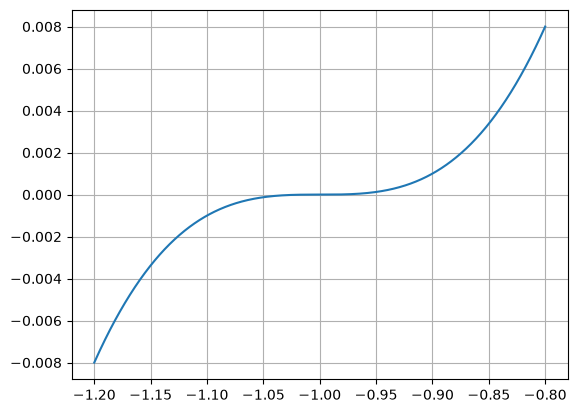

In [28]:
plt.plot(x_values, y_values)
plt.grid()

In [29]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

# Zwei symbolische Features
x1, x2 = sp.symbols('x1 x2')

# Gleichung
f = x1**2 - sp.sin(x2**5)

# In NumPy-Funktion umwandeln
f_numeric = sp.lambdify((x1, x2), f, 'numpy')

# Wertebereich erstellen
x1_values = np.linspace(-5, 5, 100)
x2_values = np.linspace(-5, 5, 100)

# 2D-Gitter erstellen
X1, X2 = np.meshgrid(x1_values, x2_values)

# Funktionswerte für jeden Punkt berechnen
Z = f_numeric(X1, X2)

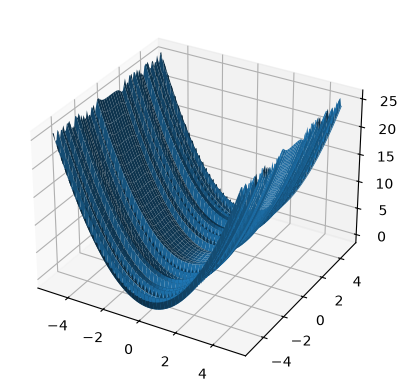

In [30]:
fig = plt.figure()

ax = fig.add_subplot(projection='3d')

ax.plot_surface(X1, X2, Z)
plt.show()

In [31]:
q1, q2 = sp.symbols('theta_1, theta_2')
l1, l2 = sp.symbols('l_1, l_2')

In [33]:
TEE_1 = sp.Matrix([[sp.cos(q2), -sp.sin(q2), l2*sp.cos(q2)],
                   [sp.sin(q2), sp.cos(q2), l2*sp.sin(q2)],
                   [0, 0, 1]])

T1_0 = sp.Matrix([[sp.cos(q1), -sp.sin(q1), l1*sp.cos(q1)],
                   [sp.sin(q1), sp.cos(q1), l1*sp.sin(q1)],
                   [0, 0, 1]])


TEE_0 = sp.simplify(T1_0 * TEE_1)

TEE_0

Matrix([
[cos(theta_1 + theta_2), -sin(theta_1 + theta_2), l_1*cos(theta_1) + l_2*cos(theta_1 + theta_2)],
[sin(theta_1 + theta_2),  cos(theta_1 + theta_2), l_1*sin(theta_1) + l_2*sin(theta_1 + theta_2)],
[                     0,                       0,                                             1]])

In [35]:
X = TEE_0[0:2, 2]
X

Matrix([
[l_1*cos(theta_1) + l_2*cos(theta_1 + theta_2)],
[l_1*sin(theta_1) + l_2*sin(theta_1 + theta_2)]])

In [37]:
x, y = sp.symbols('x, y')

In [43]:
# res = sp.solve ((X[0]-x, X[1]-y), (q1,q2))
J = X.jacobian((q1, q2))
J

Matrix([
[-l_1*sin(theta_1) - l_2*sin(theta_1 + theta_2), -l_2*sin(theta_1 + theta_2)],
[ l_1*cos(theta_1) + l_2*cos(theta_1 + theta_2),  l_2*cos(theta_1 + theta_2)]])

In [46]:
Ffun = sp.lambdify((q1, q2), J,'numpy')


Ffun(0,0)


array([[0, 0],
       [1.0*l_1 + 1.0*l_2, 1.0*l_2]], dtype=object)